<center>
Міністерство освіти і науки України<br>
Національний технічний університет України<br>
«Київський політехнічний інститут імені Ігоря Сікорського»<br>
Факультет інформатики та обчислювальної техніки<br>
Кафедра інформаційних систем та технологій<br>
</center>

<br><br><br>

<center>
Лабораторні роботи №7, 8, 12<br>
з дисципліни<br>
Штучний інтелект в задачах обробки зображень<br>
</center>

<br><br><br>

<left>
Виконав:<br>
студент групи ІА-34:<br>
Ястремський Богдан<br>
</left>

<br>

<right>
Перевірив:<br>
асистент кафедри ІСТ<br>
Тюляков Д.І.<br>
</right>

<br>

<center>Київ 2026</center>

### Тема
Покращення якості зображень шляхом використання генеративних моделей.  
Генерування зображень за допомогою Stable Diffusion v1-5.  
Стилізація зображень під картини відомих художників.

### Мета
Навчитись використовувати генеративні змагальні мережі (GAN) для покращення якості зображень з використанням бібліотеки TensorFlow.  
Навчитися працювати з пакетом diffusers для Stable Diffusion.  
Ознайомлення зі стилізацією зображень під картини мистецтва.

**Короткі теоретичні відомості:**
<p>Генеративні змагальні мережі (англ. Generative adversarial networks, GANs) — це клас алгоритмів штучного інтелекту, що використовуються в навчанні без учителя, реалізовані системою двох штучних нейронних мереж, які змагаються одна з одною в рамках гри з нульовою сумою. Вони були запроваджені Яном Ґудфелоу в 2014 році. Ця методика дозволяє створювати фотографії, які для побіжного огляду людиною виглядають як справжні та мають багато реалістичних елементів (хоча в тестах люди можуть відрізнити реальні зображення від згенерованих у багатьох випадках). ESRGAN (Enhanced Super-Resolution Generative Adversarial Network) - це покращена версія Super-Resolution Generative Adversarial Network (SRGAN), яка використовується для відновлення високої роздільної здатності (Super-Resolution) зображень.</p>

<p>Stable Diffusion — це прихована модель дифузії тексту в зображення, здатна генерувати фотореалістичні зображення за будь-якого введення тексту. Дифузійні моделі (також відомі як ймовірнісні моделі дифузії) генерують зображення (або інші типи даних), намагаючись реконструювати зображення з оригіналу з додаванням шуму (гауссового шуму).</p>

<p>Стилізація зображень через перенесення стилю - це процес застосування художнього стилю одного зображення (стилізованого зображення) до вмісту іншого зображення (вмістового зображення) за допомогою глибоких нейронних мереж. Цей підхід використовується в різних областях, таких як мистецтво, дизайн та обробка зображень. Основна ідея полягає в тому, щоб створити нове зображення, яке містить вміст оригінального зображення, але відображає стиль іншого.</p>


### Хід роботи
<center>7 Лабораторна Робота</center>

<p>Першим ділом підтягнемо всі необхідні бібліотеки для роботи, завантажимо натреновану модель ESRGAN. Визначимо функцію малювання графіків, в нашому випадку – без осей і з назвою.</p>

<p>Далі визначимо функцію обробки картинки. Декодуємо файл у тензор,. обрізаємо альфа-канал і зображення, щоб висота і ширина кратно ділились на 4 (ESRGAN приймає саме такі розміри).</p>

<p>Далі перетворюємо все у float.32, і додаємо batch-вимір у наш тензор: буде (1, w, h, c)</p>

<p>Далі проганяємо нашу картинку через модельку і видаляємо наш batch. Далі додаємо вивід у файл: обмежуємо розмір графіка, задаємо 1 рядок і 2 колонки для зображень, і зберігаємо у файл. </p>

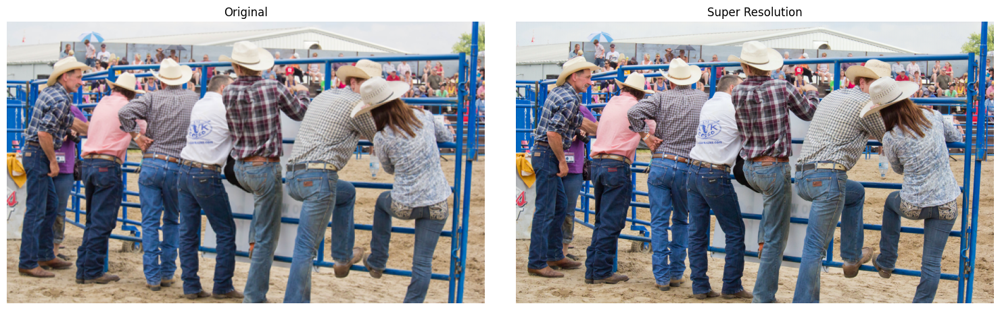

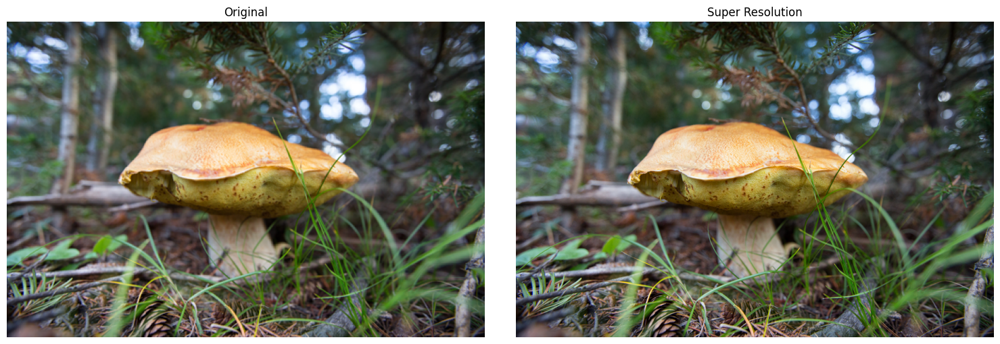

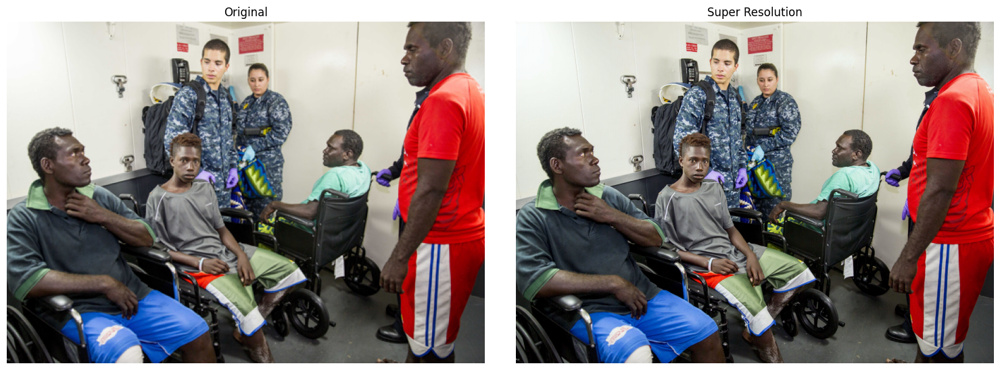

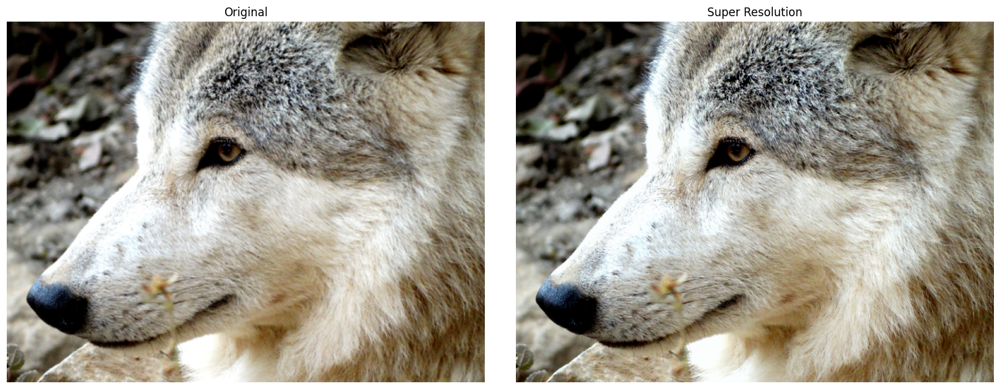

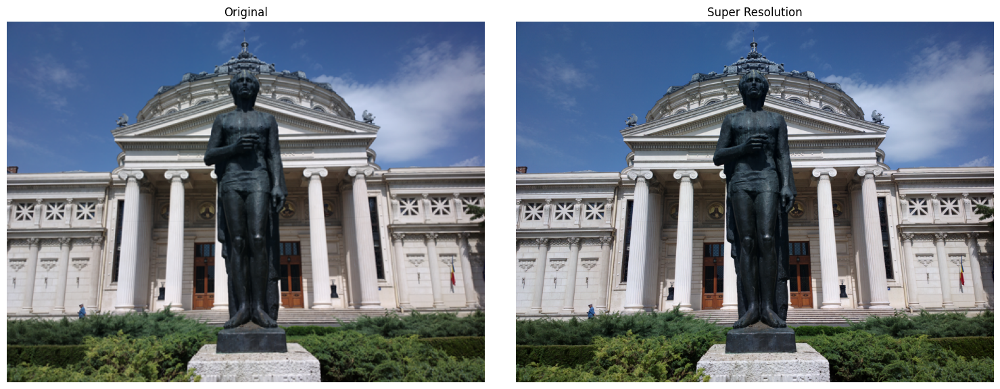

...

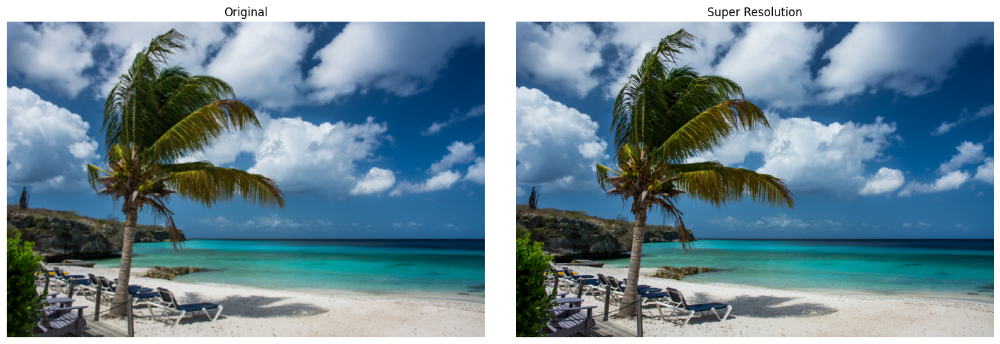

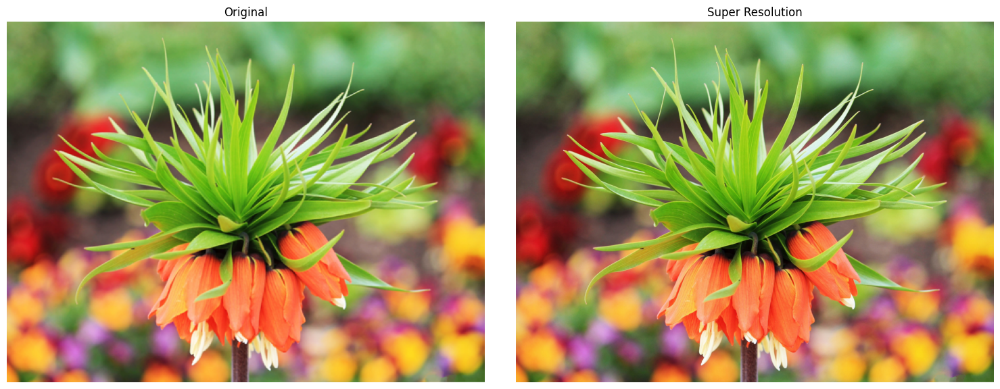

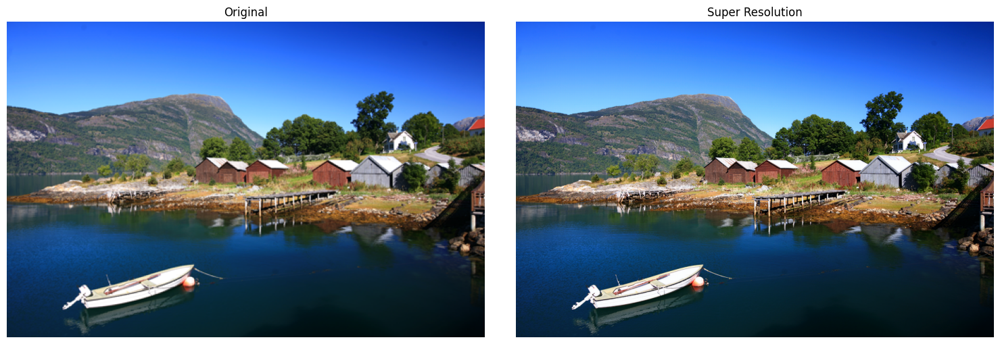

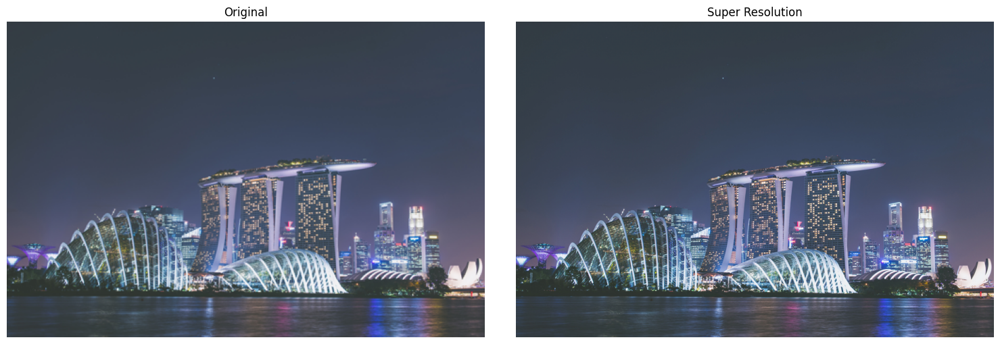

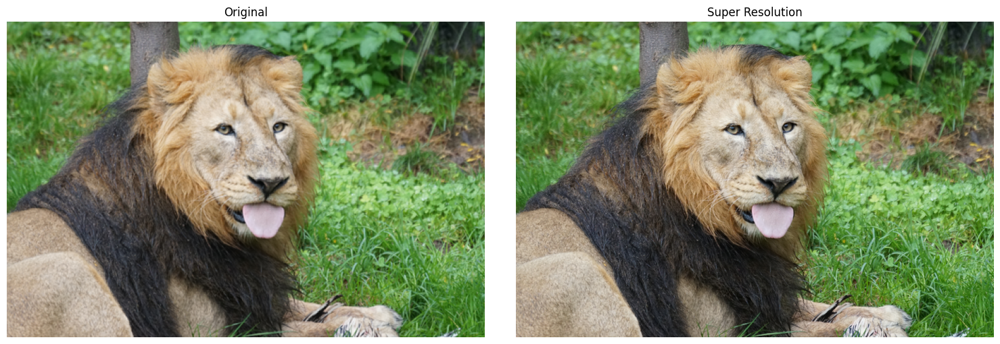

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import tensorflow_hub as hub
from PIL import Image
from pathlib import Path
import os


model = hub.load("https://tfhub.dev/captain-pool/esrgan-tf2/1")
path = "/kaggle/input/datasets/bodyastar/esrgan-test-images/"


def plot_image(image, title=""):
    image = np.asarray(image)
    image = tf.clip_by_value(image, 0, 255)
    image = Image.fromarray(tf.cast(image, tf.uint8).numpy())
    plt.imshow(image)
    plt.axis("off")
    plt.title(title)


def process_image(image_path):
    image_path = str(image_path)
    original_image = tf.image.decode_image(tf.io.read_file(image_path))

    # Clipping PNG alpha-channel
    if original_image.shape[-1] == 4:
        original_image = original_image[..., :-1]

    hr_size = (tf.convert_to_tensor(original_image.shape[:-1]) // 4) * 4
    original_image = tf.image.crop_to_bounding_box(original_image,
                                                   0,
                                                   0,
                                                   hr_size[0],
                                                   hr_size[1])
    original_image = tf.cast(original_image, tf.float32)
    original_image = tf.expand_dims(original_image, 0)

    enhanced_image = model(original_image)
    enhanced_image = tf.squeeze(enhanced_image)

    plt.rcParams['figure.figsize'] = [15, 10]
    fig, axes = plt.subplots(1, 2)
    fig.tight_layout()

    plt.subplot(1, 2, 1)
    plot_image(tf.squeeze(original_image), title="Original")

    plt.subplot(1, 2, 2)
    plt.tight_layout()
    plot_image(tf.squeeze(enhanced_image), "Super Resolution")

    output_dir = "/kaggle/working/"
    filename = os.path.basename(image_path)
    plt.savefig(output_dir + "ENHANCED_" + filename, bbox_inches="tight")


folder = Path(path)
for file_path in folder.iterdir():
    if file_path.is_file():
        process_image(file_path)

<center>8 Лабораторна Робота</center>

#### Створення зображення за промтом. Перегляд результату зображень за промтом. Створення зображення за промтом з параметрами.

- height/width: за замовчуванням 512х512, можна змінити на кратні 8
- guidance_scale: чим менше, тим більше нейронка "креативить"


In [6]:
from diffusers import StableDiffusionPipeline
import torch
from google.colab.patches import cv2_imshow
import cv2

model_id = "runwayml/stable-diffusion-v1-5"
pipe = StableDiffusionPipeline.from_pretrained(model_id, torch_dtype=torch.float16).to("cuda")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/50 [00:00<?, ?it/s]

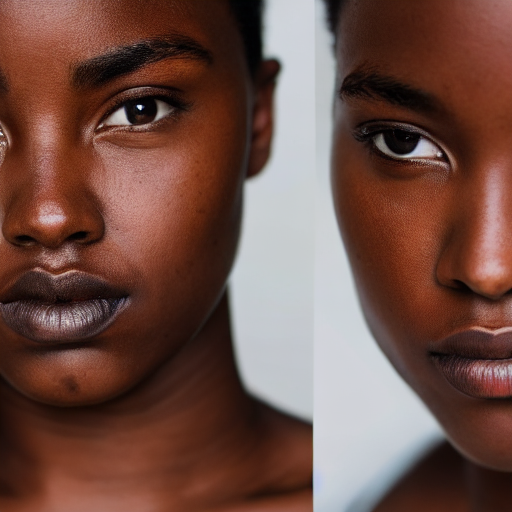

  0%|          | 0/50 [00:00<?, ?it/s]

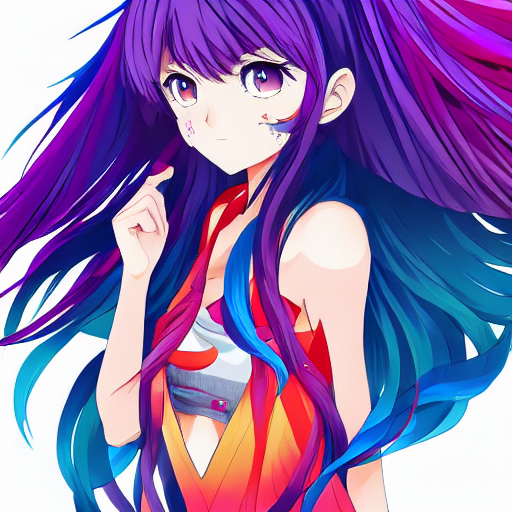

  0%|          | 0/50 [00:00<?, ?it/s]

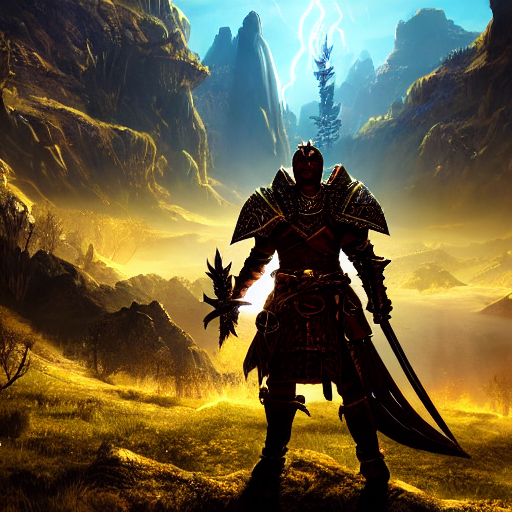

  0%|          | 0/50 [00:00<?, ?it/s]

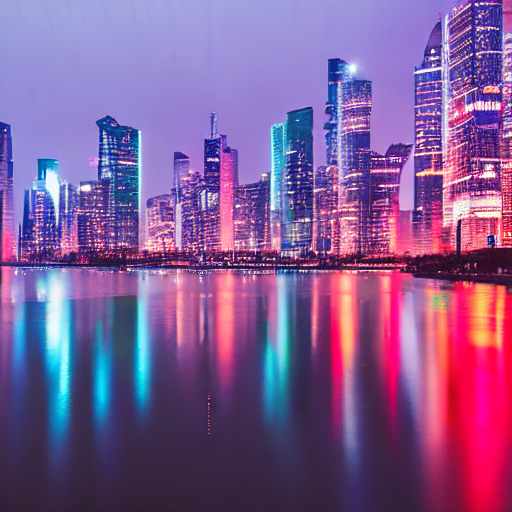

  0%|          | 0/50 [00:00<?, ?it/s]

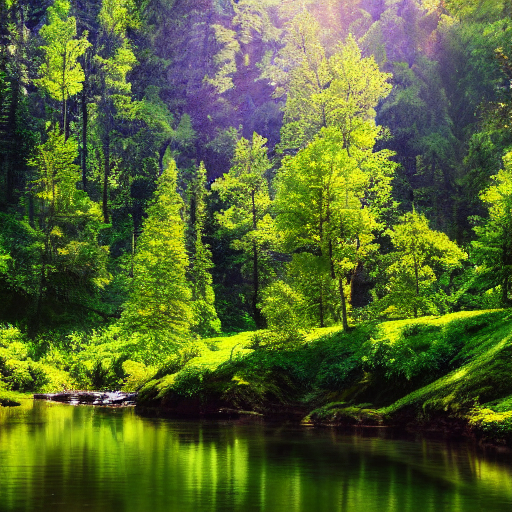

  0%|          | 0/50 [00:00<?, ?it/s]

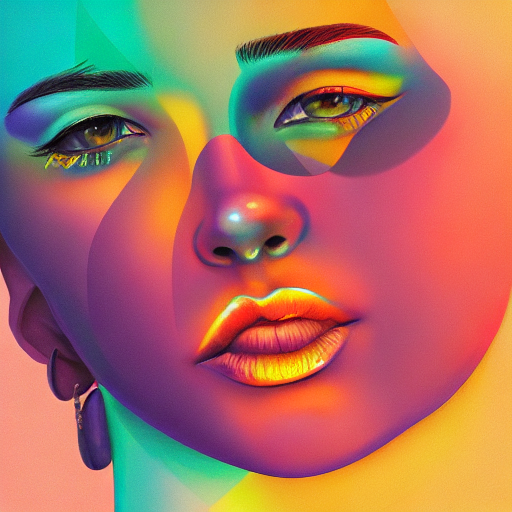

In [7]:
prompts = {
    "realistic": "portrait photo of a young person, natural lighting, detailed skin, shallow depth of field, 50mm lens, ultra realistic, 4k",
    "anime": "anime character, colorful hair, expressive eyes, dynamic pose, vibrant colors, clean lineart, soft shading, high detail",
    "fantazy": "fantasy warrior in armor, glowing sword, epic landscape, mountains, dramatic sky, cinematic lighting, highly detailed",
    "cyberpunk": "cyberpunk city at night, neon lights, futuristic buildings, rain, reflections, cinematic, ultra detailed, 4k",
    "nature": "beautiful landscape, river, green forest, sunlight rays, peaceful atmosphere, ultra realistic, high detail, 4k",
    "digital-art": "digital art illustration, soft lighting, detailed shading, vibrant colors, trending on artstation, masterpiece"
}

negative_prompt = "blurry, low quality, bad anatomy, extra limbs, deformed, watermark, text"

for name, prompt in prompts.items():
  image = pipe(prompt=prompt, negative_prompt=negative_prompt,
             guidance_scale=7, height=512, width=512).images[0]
  path = f"{name}.png"
  image.save(path)
  img = cv2.imread(path)
  cv2_imshow(img)

#### Створення зображення на основі іншого зображення

<p>Початкове зображення кодується в латентний простір і до нього
додається шум. Потім модель прихованої дифузії приймає підказку та зашумлене
приховане зображення, прогнозує доданий шум і видаляє передбачений шум із
початкового прихованого зображення, щоб отримати нове приховане зображення.</p>


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/40 [00:00<?, ?it/s]

Saved to: /kaggle/working/UPDATED_girl.png


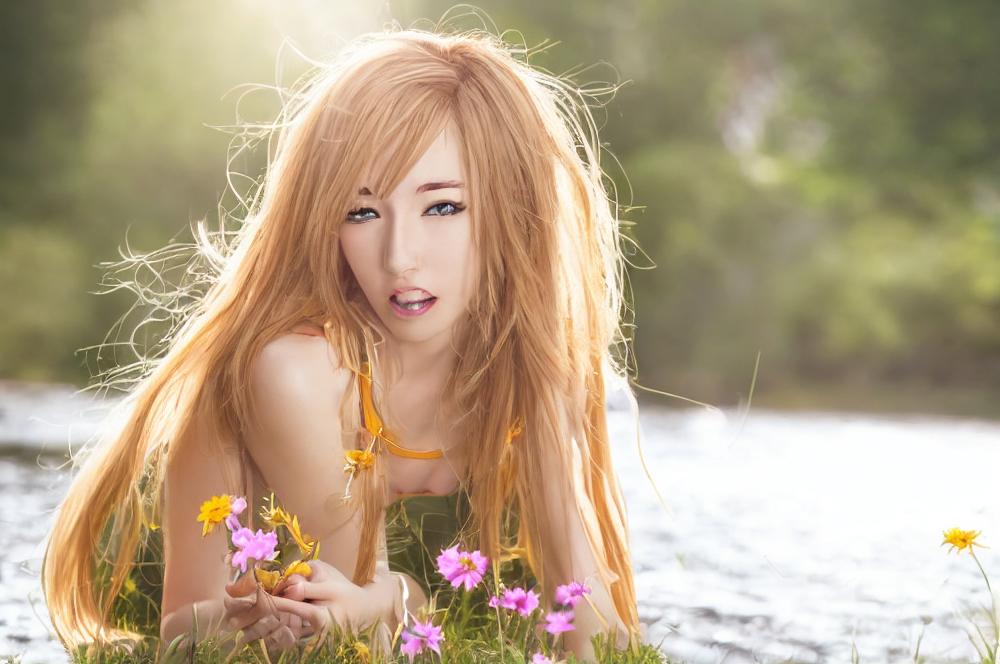

In [2]:
import os
import torch
import cv2
from diffusers import StableDiffusionImg2ImgPipeline 
from diffusers.utils import make_image_grid, load_image

from google.colab.patches import cv2_imshow


model_id = "runwayml/stable-diffusion-v1-5"

pipe = StableDiffusionImg2ImgPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    use_safetensors=True
)

pipe.enable_model_cpu_offload()

img_path = "/kaggle/input/datasets/bodyastar/img2imgprediffusedimages/girl.png"
filename = os.path.basename(img_path)

init = load_image(img_path)

prompt = "anime girl with blonde hair and playful expression, lying on green grass near a river, sunny day, nature background, soft breeze, flowers around, relaxed pose, vibrant colors, detailed, high quality, anime style"

result = pipe(prompt, image=init).images[0]

output_dir = "/kaggle/working"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, "UPDATED_" + filename)
result.save(output_path)

grid = make_image_grid([init, result], rows=1, cols=2)
grid.save(os.path.join(output_dir, "GRID_" + filename))

print("Saved to:", output_path)

cv2_imshow(cv2.imread(output_path))

  0%|          | 0/40 [00:00<?, ?it/s]

Saved to: /kaggle/working/UPDATED_photo_2023-08-18_21-55-29.jpg


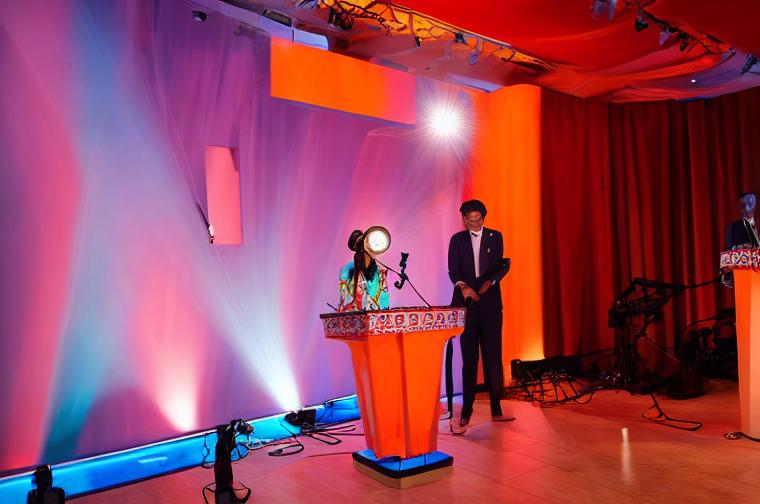

In [5]:
img_path = "/kaggle/input/datasets/bodyastar/img2imgprediffusedimages/photo_2023-08-18_21-55-29.jpg"
filename = os.path.basename(img_path)

init = load_image(img_path)

prompt = "a vibrant event stage partially submerged in a calm turquoise sea, two presenters standing in shallow water, one wearing a bright orange patterned suit with white designs and sunglasses, holding a microphone"
result = pipe(prompt=prompt, image=init, negative_prompt=negative_prompt, guidance_scale=7).images[0]

output_dir = "/kaggle/working"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, "UPDATED_" + filename)
result.save(output_path)

grid = make_image_grid([init, result], rows=1, cols=2)
grid.save(os.path.join(output_dir, "GRID_" + filename))

print("Saved to:", output_path)

cv2_imshow(cv2.imread(output_path))

<center>12 Лабораторна Робота</center>

Завантажуємо всі необхідні модулі, моделі в стиснутому форматі. Також юзаємо асинхронний алокатор пам'яті CUDA (будемо юзати GPU)

In [9]:
import os
import tensorflow as tf
import numpy as np
import PIL.Image
import IPython.display as display
import matplotlib.pyplot as plt
import matplotlib as mpl
import time
import keras

os.environ['TFHUB_MODEL_LOAD_FORMAT'] = 'COMPRESSED'
os.environ['TF_GPU_ALLOCATOR'] = 'cuda_malloc_async'

mpl.rcParams['figure.figsize'] = (12, 12)
mpl.rcParams['axes.grid'] = False

Визначимо зображення:
- яке стилізуватимемо
- стиль, який юзатимемо

In [10]:
path = "/kaggle/input/datasets/soumikrakshit/images-for-style-transfer/Data/"
style_path = path + "Artworks/108700.jpg"
content_path = path + "TestCases/22714.jpg"

Переведемо тензор у зображення ([0; 1] = [0; 255] - RGB).<br>
Завантажимо картинку і обмежимо її до 512px

In [11]:
def tensor_to_image(tensor):
    tensor = tensor * 255
    tensor = np.array(tensor, dtype=np.uint8)

    if np.ndim(tensor) > 3:
        assert tensor.shape[0] == 1
        tensor = tensor[0]

    return PIL.Image.fromarray(tensor)

def load_img(path_to_img):
    max_dim = 512
    img = tf.io.read_file(path_to_img)
    img = tf.image.decode_image(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)

    shape = tf.cast(tf.shape(img)[:-1], tf.float32)
    long_dim = max(shape)
    scale = max_dim / long_dim

    new_shape = tf.cast(shape * scale, tf.int32)

    img = tf.image.resize(img, new_shape)
    img = img[tf.newaxis, :]
    return img


def imshow(image, title=None):
    if len(image.shape) > 3:
        image = tf.squeeze(image, axis=0)

    plt.imshow(image)

    if title:
        plt.title(title)

Виведемо отримані картинки та їхню статистику

Content shape: (1, 384, 512, 3)
Style shape: (1, 352, 512, 3)
Content min/max: 0.0 1.0
Style min/max: 0.0 0.9964729


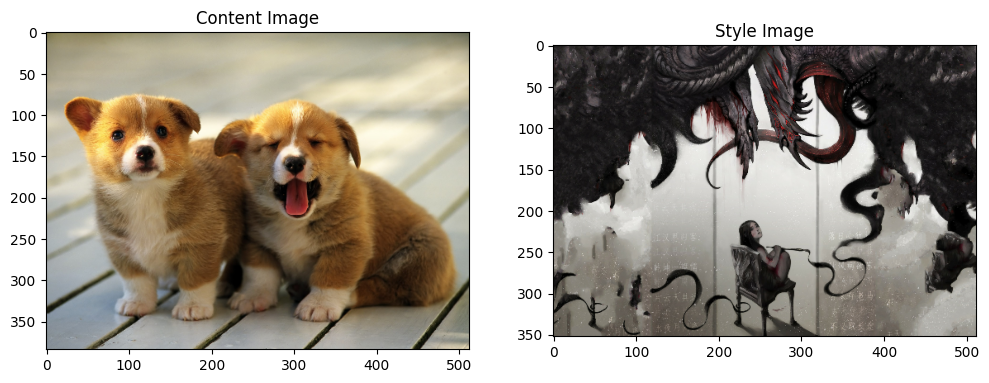

In [12]:
content_image = load_img(content_path)
style_image = load_img(style_path)

print("Content shape:", content_image.shape)
print("Style shape:", style_image.shape)
print("Content min/max:", tf.reduce_min(content_image).numpy(), tf.reduce_max(content_image).numpy())
print("Style min/max:", tf.reduce_min(style_image).numpy(), tf.reduce_max(style_image).numpy())

plt.subplot(1, 2, 1)
imshow(content_image, "Content Image")

plt.subplot(1, 2, 2)
imshow(style_image, "Style Image")
plt.show()

Підготовка зображення для VGG19: `preprocess_input` змінює порядок на BGR, З кожного пікселя віднімається середня яскравість (по окремих каналах), яка була вирахувана на мільйонах зображень бази ImageNet.<br>
Також змасштабуємо зображення до 224×224px

In [13]:
x = keras.applications.vgg19.preprocess_input(content_image*255)
x = tf.image.resize(x, (224, 224))

Визначаємо шари контенту і стилю.

![Alt Text](https://www.mdpi.com/agriengineering/agriengineering-04-00056/article_deploy/html/images/agriengineering-04-00056-g002.png)

З контенту ми беремо лише останній найглибший шар - те, що ми хочемо зберегти.

Зі стилів ми позичаємо:
1. Базові деталі: краї, лінії і тд.
2. Прості текстури
3. Складні патерни
4. Об'єкти + їхні частини
5. Що взагалі визначає композицію

In [14]:
content_layers = ['block5_conv2']

style_layers = ['block1_conv1',
                'block2_conv1',
                'block3_conv1',
                'block4_conv1',
                'block5_conv1',]

num_content_layers = len(content_layers)
num_style_layers = len(style_layers)

Створимо модель VGG19, яка замість класифікації зображень просто повертатиме карти ознак (feature maps) з потрібних нам шарів. <br>
Завантажуємо архітектуру VGG19. <br>
`weights='imagenet'` означає, що мережа вже попередньо натренована на мільйонах зображень. <br>
`include_top=False` відрізає останні класифікаційні шари (Fully Connected), оскільки для перенесення стилю нас цікавить лише те, як мережа "бачить" зображення на етапі згорток.
<br><br>
Далітреба обчислити матрицю Грама (Gram matrix). У задачах перенесення стилю матриця Грама використовується для математичного опису стилю або текстури зображення, ігноруючи при цьому конкретні об'єкти (контент).
<br>
Операція bijc,bijd->bcd множить кожен канал $c$ на кожен канал $d$ по всіх пікселях (висоті $i$ та ширині $j$) і сумує результат.

Формула матриці Грама:
$$G_{cd} = \frac{1}{H \times W} \sum_{i=1}^{H} \sum_{j=1}^{W} F_{ijc} F_{ijd}$$

In [15]:
def vgg_layers(layer_names):
    vgg = keras.applications.VGG19(include_top=False, weights='imagenet')
    vgg.trainable = False

    outputs = [vgg.get_layer(name).output for name in layer_names]

    model = keras.Model([vgg.input], outputs)
    return model


def gram_matrix(input_tensor):
    result = tf.linalg.einsum('bijc,bijd->bcd', input_tensor, input_tensor)
    input_shape = tf.shape(input_tensor)
    num_locations = tf.cast(input_shape[1]*input_shape[2], tf.float32)

    return result / num_locations

Створимо модель, яка повертає тензори стилю та вмісту.

In [16]:
class StyleContentModel(keras.models.Model):
    def __init__(self, style_layers, content_layers):
        super(StyleContentModel, self).__init__()
        self.vgg = vgg_layers(style_layers + content_layers)
        self.style_layers = style_layers
        self.content_layers = content_layers
        self.num_style_layers = num_style_layers
        self.vgg.trainable = False

    def call(self, inputs):
        inputs = inputs*255.0
        preprocessed_input = keras.applications.vgg19.preprocess_input(inputs)
        outputs = self.vgg(preprocessed_input)
        style_outputs, content_outputs = (outputs[:self.num_style_layers],
                                          outputs[self.num_style_layers:])

        style_outputs = [gram_matrix(style_output)
                         for style_output in style_outputs]

        content_dict = {content_name: value
                        for content_name, value
                        in zip(self.content_layers, content_outputs)}

        style_dict = {style_name: value
                        for style_name, value
                        in zip(self.style_layers, style_outputs)}

        return {
            'content': content_dict,
            'style': style_dict
        }

Далі робимо:
- Встановлення цільових значень стилю та вмісту: матриці Грама для стилю і карти ознак для контенту.
- Зображення як змінну: будемо його змінювати під наш стиль. Також обріжемо його в діапазон [0; 1].
- Визначимо оптимізатор Adam.

In [17]:
extractor = StyleContentModel(style_layers, content_layers)

style_targets = extractor(style_image)['style']
content_targets = extractor(content_image)['content']

image = tf.Variable(content_image)


def clip_0_1(image):
    return tf.clip_by_value(image, clip_value_min=0.0, clip_value_max=1.0)


opt = keras.optimizers.Adam(learning_rate=0.02, beta_1=0.99, epsilon=1e-1)

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Задаємо ваги стилю та контенту.

In [18]:
style_weight = 1e-2
content_weight = 1e4

Визначимо функцію втрат для контену і стилю.<br>
- `get_content_loss` та `get_style_loss` рахують середньоквадратичну помилку між поточним станом image та нашими еталонами.
- `style_content_loss` = сума помилок по всіх обраних шарах.

In [19]:
def get_content_loss(base_content, target):
    return tf.reduce_mean(tf.square(base_content - target))


def get_style_loss(gram_style, gram_target):
    return tf.reduce_mean(tf.square(gram_style - gram_target))


def style_content_loss(outputs):
    style_outputs = outputs['style']
    content_outputs = outputs['content']

    style_loss = tf.add_n([
        get_style_loss(style_outputs[name], style_targets[name])
        for name in style_outputs.keys()
    ])
    style_loss *= style_weight / num_style_layers

    content_loss = tf.add_n([
        get_content_loss(content_outputs[name], content_targets[name])
        for name in content_outputs.keys()
    ])
    content_loss *= content_weight / num_content_layers

    return style_loss + content_loss

Виконуємо згладжування.<br>
Використовуємо градієнт для того, щоб вирахувати загальну помилку (стиль + контент + шум) і визначає градієнти (куди треба потягнути кольори пікселів).


In [20]:
total_variation_weight = 15


@tf.function()
def train_step(image):
    with tf.GradientTape() as tape:
        outputs = extractor(image)
        loss = style_content_loss(outputs)
        loss += total_variation_weight * tf.image.total_variation(image)

    grad = tape.gradient(loss, image)
    opt.apply_gradients([(grad, image)])
    image.assign(clip_0_1(image))

Виконуємо навчання.

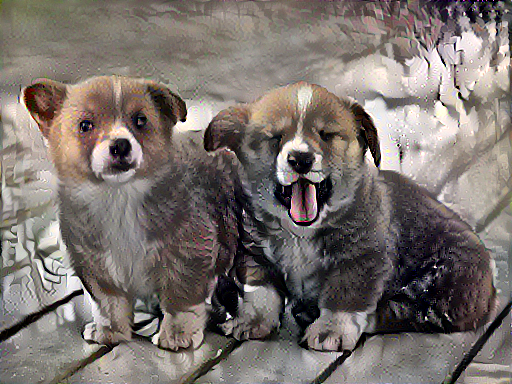

Train step: 500
Total time: 41.929890632629395.1f


In [21]:
start = time.time()
epochs = 10
steps_per_epoch = 50
step = 0

# Діагностика перед навчанням
test_outputs = extractor(content_image)
style_out = test_outputs['style']
content_out = test_outputs['content']

print("Style losses:")
for name, val in style_out.items():
    print(f"{name}: {tf.reduce_mean(val).numpy():.4f}")

print("Content losses:")
for name, val in content_out.items():
    print(f"{name}: {tf.reduce_mean(val).numpy():.4f}")

for n in range(epochs):
    for m in range(steps_per_epoch):
        step += 1
        train_step(image)
        print(".", end='', flush=True)
    display.clear_output(wait=True)
    display.display(tensor_to_image(image))
    print(f"Train step: {format(step)}")

end = time.time()
print(f"Total time: {(end - start):.1f}")

output_dir = "/kaggle/working/"
file_name = output_dir + "NST-test-1.jpg"
tensor_to_image(image).save(file_name)

### Висновок
На даному лабораторному занятті я познайомився із влаштуванням генеративних моделей (такі як ESRGAN та Stable-Diffusion v1.5) і згорткових нейронних мереж (VGG19).

Лабораторна робота із ESGRAN була призвана, щоб допомогти покращити якість зображень, яка була втрачена під час стиснення, розмиття, чи шуму. В моєму випадку було використано відомий датасету DIV2K, який є стандартом для задач Super-Resolution. Деякі зображення у висновку, дійсно вдалося покращити, не дивлячись на те, що matplotlib теж стискує зображення, що може давати певні завади.

Лабораторна робота із Stable-Diffusion v1.5 по суті є гарним тренажером для написання точних промптів, щоб зображення хоча б приблизно вийшло таким, яким було його описано. Я розібрав звичайний текстовий промпт та промпт на основі вже заданого зображення. Дуже важливим є не тільки промпт, але й параметри моделі, які можуть суттєво вплинути на результат.

Лабораторна робота із VGG19 є найскладнішою частиною, як в теорії, так і в реалізації. Хоча ззовні вона виглядає як система з двома входами - фото + стиль, під капотом сховані дуже великі обчислення, і доволі складна логіка роботи. Налаштування параметрів так само суттєво впливає на результат переносу стилю.

### Відповіді на контрольні питання:
<hr>

1. **Що таке GAN?** GAN (Generative Adversarial Network) — це тип нейронної мережі, яка вміє генерувати нові дані, схожі на реальні (зображення, звук тощо).
2. **Який принцип роботи GAN?** Є дві мережі, які змагаються між собою: одна генерує фейкові дані, інша перевіряє, чи вони справжні - через це генерація стає все кращою
3. **Які два основних компонента складають архітектуру GAN?** Генератор (Generator) — створює фейкові дані. Дискримінатор (Discriminator) — визначає: реальні чи фейкові
4. **Як проходить процес навчання GAN?** Генератор створює фейкові дані. Дискримінатор порівнює їх з реальними. Дискримінатор вчиться краще розпізнавати. Генератор вчиться краще обманювати
5. **Які в GAN застосування?** Заповнення пропусків у зображеннях. Покращення якості зображень. Генерація музики та звуків.

<hr>

6. **Як працюють дифузійні моделі?** Дифузійні моделі (також відомі як ймовірнісні моделі дифузії) генерують зображення (або інші типи даних), намагаючись реконструювати зображення з оригіналу з додаванням шуму (гауссового шуму).
7. **Для чого використовується Negative prompt?** Негативна підказка відводить модель від речей, які ми не хочемо, щоб модель створювала.
8. **Для чого використовуємо Guidance scale у даній лабораторній?** Це параметр, який визначає, наскільки суворо нейромережа має дотримуватися промпту при створенні зображення. Вищі значення змушують модель точніше слідувати запиту, але можуть знизити різноманітність та якість, тоді як нижчі — дають більше творчої свободи. 
9. **Як необхідно задавати промти та для чого вони використовуються?** Промт - це короткий набір інструкцій, що описує зображення, яке ми хочете побачити.
10. **Що таке Diffusers?** Diffusers — це основна бібліотека для найсучасніших попередньо навчених
моделей дифузії.

<hr>

11. **Що таке стилізація зображень і які її основні застосування?** Це перенесення стилю одного зображення (наприклад, картини) на інше зображення (контент). Застосування: художні ефекти (як картини художників), фільтри (Instagram-подібні)
12. **Які є основні етапи процесу Neural Style Transfer?** Вибір content image і style image. Пропуск через CNN (наприклад, VGG19). Витяг ознак (features). Обчислення втрат (content + style). Оптимізація зображення (оновлення пікселів)
13. **Яку роль відіграє функція втрат у Neural Style Transfer?** Content loss — зберігає структуру. Style loss — переносить стиль. Total variation loss — згладжує шум
14. **Які є способи регуляризації стилізованого зображення?** Total Variation Loss — прибирає шум. Згладжування (blur). Обмеження значень пікселів
15. **Які ще моделі, окрім VGG19, можна використовувати для вилучення ознак зображень у Neural Style Transfer?** *ResNet* - використовують «залишкові зв'язки» (skip-connections), що дозволяє будувати набагато глибші мережі без втрати якості навчання. *EfficientNet* - Значно швидше працює на мобільних пристроях та серверах з обмеженими ресурсами. 